In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import pickle

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
BASE_DIR = Path("..")

DATA_PATH = BASE_DIR / "data" / "Reviews.csv"
MODEL_PATH = BASE_DIR / "models" / "sentiment_model.pkl"
IMAGE_PATH = BASE_DIR / "images" / "confusion_matrix.png"

MODEL_PATH.parent.mkdir(exist_ok=True)
IMAGE_PATH.parent.mkdir(exist_ok=True)

print(DATA_PATH)

..\data\Reviews.csv


In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (568454, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [4]:
print(df.isnull().sum())
print(df["Score"].value_counts().sort_index())

Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64
Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64


In [5]:
df = df[df["Score"] != 3].copy()

df["sentiment"] = df["Score"].apply(
    lambda x: 1 if x >= 4 else 0
)

print(df["sentiment"].value_counts())

sentiment
1    443777
0     82037
Name: count, dtype: int64


In [6]:
df = df[["Text", "Score", "sentiment"]]

df = df.dropna(subset=["Text"])
df = df.drop_duplicates(subset=["Text"])

print("Final Dataset Shape:", df.shape)

df.head()

Final Dataset Shape: (363836, 3)


,Text,Score,sentiment
0,I have bought several of the Vitality canned d...,5,1
1,Product arrived labeled as Jumbo Salted Peanut...,1,0
2,This is a confection that has been around a fe...,4,1
3,If you are looking for the secret ingredient i...,2,0
4,Great taffy at a great price. There was a wid...,5,1


In [7]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_text"] = df["Text"].apply(clean_text)

df[["Text", "clean_text", "sentiment"]].head()

,Text,clean_text,sentiment
0,I have bought several of the Vitality canned d...,i have bought several of the vitality canned d...,1
1,Product arrived labeled as Jumbo Salted Peanut...,product arrived labeled as jumbo salted peanut...,0
2,This is a confection that has been around a fe...,this is a confection that has been around a fe...,1
3,If you are looking for the secret ingredient i...,if you are looking for the secret ingredient i...,0
4,Great taffy at a great price. There was a wid...,great taffy at a great price there was a wide ...,1


In [8]:
X = df["clean_text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", len(X_train))
print("Testing:", len(X_test))

Training: 291068
Testing: 72768


In [9]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", LogisticRegression(
        max_iter=1000
    ))
])

In [10]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [11]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print()
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

Accuracy: 0.9287873790677221

              precision    recall  f1-score   support

    Negative       0.87      0.64      0.74     11414
    Positive       0.94      0.98      0.96     61354

    accuracy                           0.93     72768
   macro avg       0.90      0.81      0.85     72768
weighted avg       0.93      0.93      0.92     72768



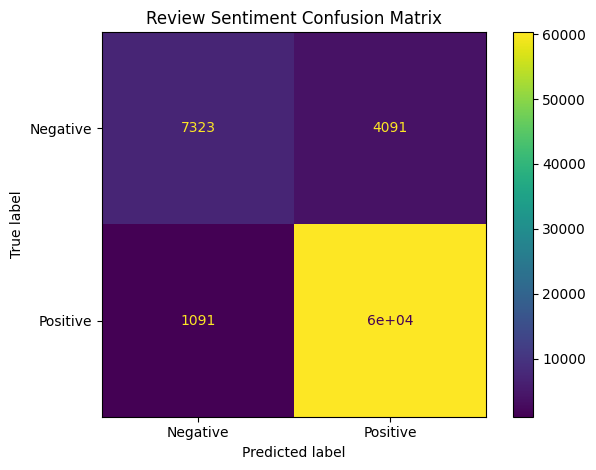

Confusion matrix saved successfully!


In [12]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.title("Review Sentiment Confusion Matrix")
plt.tight_layout()

plt.savefig(IMAGE_PATH)

plt.show()

print("Confusion matrix saved successfully!")

In [13]:
with open(MODEL_PATH, "wb") as file:
    pickle.dump(model, file)

print("Model saved at:")
print(MODEL_PATH)

Model saved at:
..\models\sentiment_model.pkl


In [14]:
test_reviews = [
    "This product is amazing and I really love it",
    "Excellent quality and very fast delivery",
    "I am very happy with this product",
    
    "This product is terrible and completely useless",
    "Very bad quality, I hate this product",
    "Worst product I have ever purchased"
]

predictions = model.predict(test_reviews)
probabilities = model.predict_proba(test_reviews)

for review, prediction, probability in zip(
    test_reviews,
    predictions,
    probabilities
):
    sentiment = "Positive 😊" if prediction == 1 else "Negative 😞"
    
    confidence = probability[prediction] * 100
    
    print("Review:", review)
    print("Prediction:", sentiment)
    print("Confidence:", round(confidence, 2), "%")
    print("-" * 70)

Review: This product is amazing and I really love it
Prediction: Positive 😊
Confidence: 99.74 %
----------------------------------------------------------------------
Review: Excellent quality and very fast delivery
Prediction: Positive 😊
Confidence: 99.85 %
----------------------------------------------------------------------
Review: I am very happy with this product
Prediction: Positive 😊
Confidence: 98.56 %
----------------------------------------------------------------------
Review: This product is terrible and completely useless
Prediction: Negative 😞
Confidence: 99.66 %
----------------------------------------------------------------------
Review: Very bad quality, I hate this product
Prediction: Negative 😞
Confidence: 91.23 %
----------------------------------------------------------------------
Review: Worst product I have ever purchased
Prediction: Negative 😞
Confidence: 99.87 %
----------------------------------------------------------------------
